# Подготовка данных

EDA и очистка (блок 2.1 требований): структура датасетов, статистический анализ
числовых и категориальных признаков, анализ корреляций, выбросов, сбалансированности
целевой переменной, решения по очистке.

Три источника в слое raw: UCI Predict Students' Dropout and Academic Success,
OULAD (зеркало Kaggle) и синтетический контингент в формате витрин 1С:Университет
(src/data/generator.py, обоснование в docs/data_generation.md).

In [1]:
import os, sys
ROOT = os.path.abspath('..') if os.path.basename(os.getcwd()) == 'notebooks' else os.getcwd()
sys.path.insert(0, ROOT)
sys.path.insert(0, os.path.join(ROOT, 'src'))
os.chdir(ROOT)

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from utils.db import engine

pd.set_option('display.max_columns', 60)
pd.set_option('display.width', 180)
sns.set_theme(style='whitegrid', palette='deep')
eng = engine()
print('рабочий каталог:', os.getcwd())

рабочий каталог: C:\work\inno_grad


## 1. UCI: структура датасета

Файл загружен в raw «как есть» (текстовые колонки): это исходное состояние,
которое исправляет слой cleaned.

In [2]:
uci_raw = pd.read_sql('SELECT * FROM raw.uci_dropout', eng)
print('строк:', len(uci_raw), 'колонок:', uci_raw.shape[1])
uci_raw.dtypes.value_counts().to_frame('типов колонок')

строк: 4424 колонок: 37


,типов колонок
str,37


In [3]:
uci_raw.head(3).iloc[:, :10]

,marital_status,application_mode,application_order,course,daytime_evening_attendance,previous_qualification,previous_qualification_grade,nacionality,mother_s_qualification,father_s_qualification
0,1,17,5,171,1,1,122.0,1,19,12
1,1,15,1,9254,1,1,160.0,1,1,3
2,1,1,5,9070,1,1,122.0,1,37,37


### Статистика числовых признаков

Колонки приведены к числам на лету только для анализа; постоянное
преобразование делает слой cleaned.

In [4]:
num_cols = ['admission_grade', 'age_at_enrollment',
            'curricular_units_1st_sem_grade', 'curricular_units_2nd_sem_grade',
            'curricular_units_1st_sem_enrolled', 'curricular_units_2nd_sem_evaluations',
            'unemployment_rate', 'inflation_rate', 'gdp']
uci_num = uci_raw[num_cols].apply(pd.to_numeric)
uci_num.describe().T.round(2)

,count,mean,std,min,25%,50%,75%,max
admission_grade,4424.0,126.98,14.48,95.00,117.90,126.10,134.80,190.00
age_at_enrollment,4424.0,23.27,7.59,17.00,19.00,20.00,25.00,70.00
curricular_units_1st_sem_grade,4424.0,10.64,4.84,0.00,11.00,12.29,13.40,18.88
curricular_units_2nd_sem_grade,4424.0,10.23,5.21,0.00,10.75,12.20,13.33,18.57
curricular_units_1st_sem_enrolled,4424.0,6.27,2.48,0.00,5.00,6.00,7.00,26.00
curricular_units_2nd_sem_evaluations,4424.0,8.06,3.95,0.00,6.00,8.00,10.00,33.00
unemployment_rate,4424.0,11.57,2.66,7.60,9.40,11.10,13.90,16.20
inflation_rate,4424.0,1.23,1.38,-0.80,0.30,1.40,2.60,3.70
gdp,4424.0,0.00,2.27,-4.06,-1.70,0.32,1.79,3.51


### Категориальные признаки и баланс целевой переменной

course: 17 значений
application_mode: 18 значений
marital_status: 6 значений
gender: 2 значений
scholarship_holder: 2 значений
debtor: 2 значений
tuition_fees_up_to_date: 2 значений


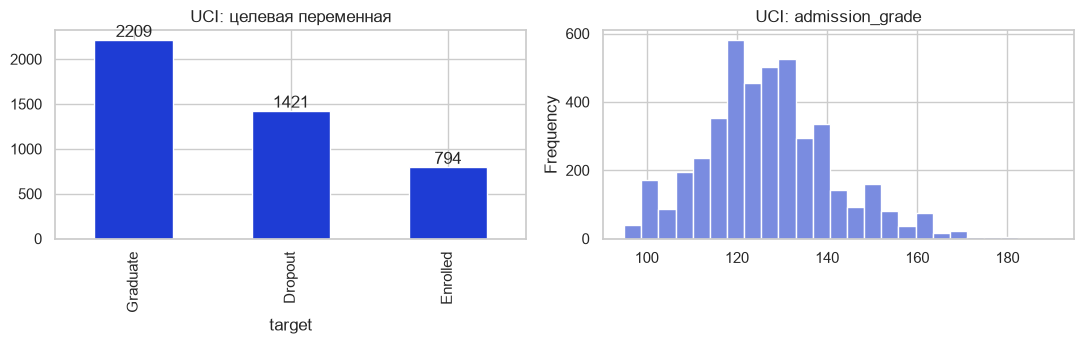

,доля
target,
Graduate,0.499
Dropout,0.321
Enrolled,0.179


In [5]:
for col in ['course', 'application_mode', 'marital_status', 'gender',
            'scholarship_holder', 'debtor', 'tuition_fees_up_to_date']:
    print(f'{col}: {uci_raw[col].nunique()} значений')

fig, axes = plt.subplots(1, 2, figsize=(11, 3.6))
uci_raw['target'].value_counts().plot.bar(ax=axes[0], color='#1E3CD4')
axes[0].bar_label(axes[0].containers[0])
axes[0].set_title('UCI: целевая переменная')
uci_num['admission_grade'].plot.hist(bins=25, ax=axes[1], color='#7A8CE0')
axes[1].set_title('UCI: admission_grade')
plt.tight_layout()
plt.show()
uci_raw['target'].value_counts(normalize=True).round(3).to_frame('доля')

### Корреляции

Целевая кодируется как Dropout = 1, остальные = 0.

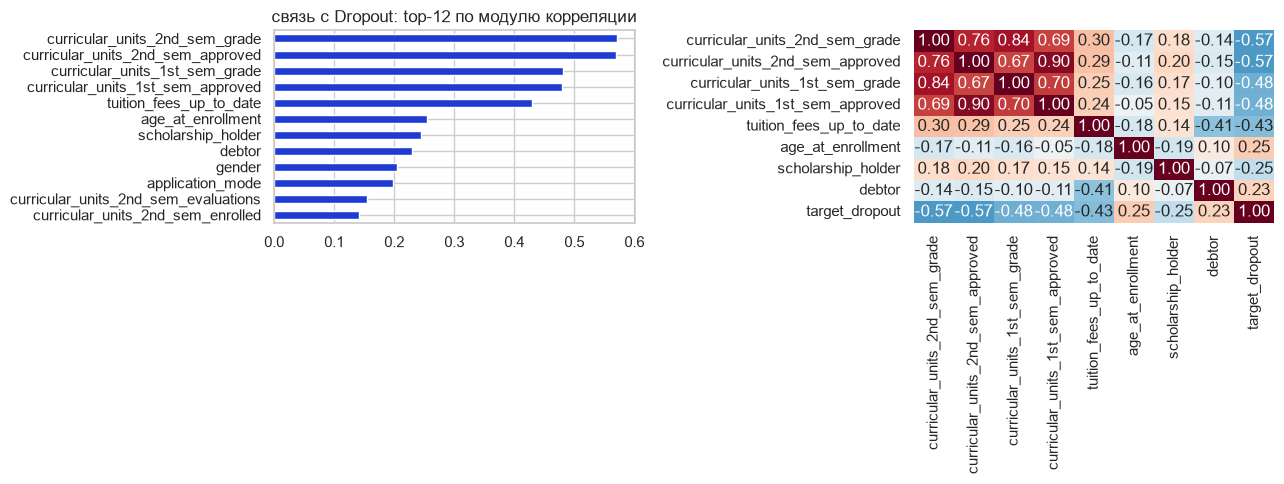

,корреляция по модулю
curricular_units_2nd_sem_grade,0.572
curricular_units_2nd_sem_approved,0.570
curricular_units_1st_sem_grade,0.481
curricular_units_1st_sem_approved,0.479
tuition_fees_up_to_date,0.429
age_at_enrollment,0.254
scholarship_holder,0.245
debtor,0.229
gender,0.204
application_mode,0.198


In [6]:
uci_full = uci_raw.copy()
uci_full['target_dropout'] = (uci_full['target'] == 'Dropout').astype(int)
uci_full = uci_full.drop(columns=['target']).apply(pd.to_numeric)
corr = uci_full.corr()
top = corr['target_dropout'].drop('target_dropout').abs().sort_values(ascending=False)

fig, axes = plt.subplots(1, 2, figsize=(13, 5))
top.head(12).sort_values().plot.barh(ax=axes[0], color='#1E3CD4')
axes[0].set_title('связь с Dropout: top-12 по модулю корреляции')
sel = top.head(8).index.tolist() + ['target_dropout']
sns.heatmap(corr.loc[sel, sel], annot=True, fmt='.2f', cmap='RdBu_r', center=0, ax=axes[1], cbar=False)
plt.tight_layout()
plt.show()
top.head(12).round(3).to_frame('корреляция по модулю')

### Выбросы

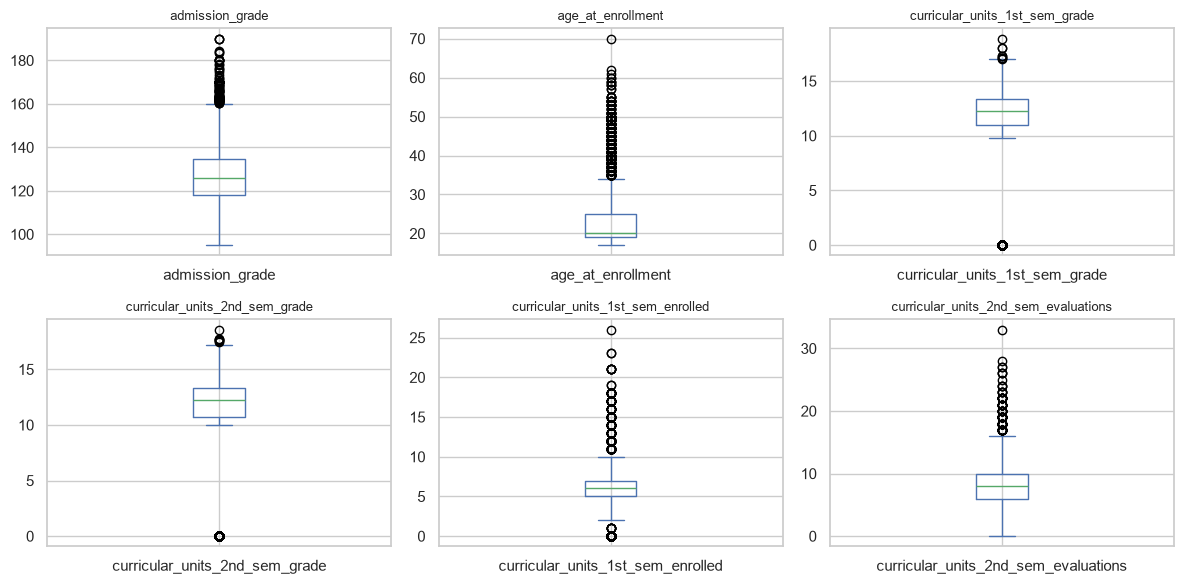

,признак,выбросов по IQR
0,admission_grade,86
1,age_at_enrollment,441
2,curricular_units_1st_sem_grade,726
3,curricular_units_2nd_sem_grade,877
4,curricular_units_1st_sem_enrolled,424
5,curricular_units_2nd_sem_evaluations,109


In [7]:
out_cols = ['admission_grade', 'age_at_enrollment',
            'curricular_units_1st_sem_grade', 'curricular_units_2nd_sem_grade',
            'curricular_units_1st_sem_enrolled', 'curricular_units_2nd_sem_evaluations']
fig, axes = plt.subplots(2, 3, figsize=(12, 6))
for ax, col in zip(axes.flat, out_cols):
    uci_num[col].plot.box(ax=ax)
    ax.set_title(col, fontsize=9)
plt.tight_layout()
plt.show()

rows = []
for col in out_cols:
    s = uci_num[col]
    q1, q3 = s.quantile([0.25, 0.75])
    iqr = q3 - q1
    rows.append({'признак': col, 'выбросов по IQR': int(((s < q1 - 1.5 * iqr) | (s > q3 + 1.5 * iqr)).sum())})
pd.DataFrame(rows)

## 2. OULAD: структура и баланс

Датасет на уровне «студент, модуль, семестр презентации», итог
final_result включает Pass, Distinction, Fail, Withdrawn.

студенто-модулей: 32593 уникальных студентов: 28785
пропусков imd_band: 1111 (3.4%)


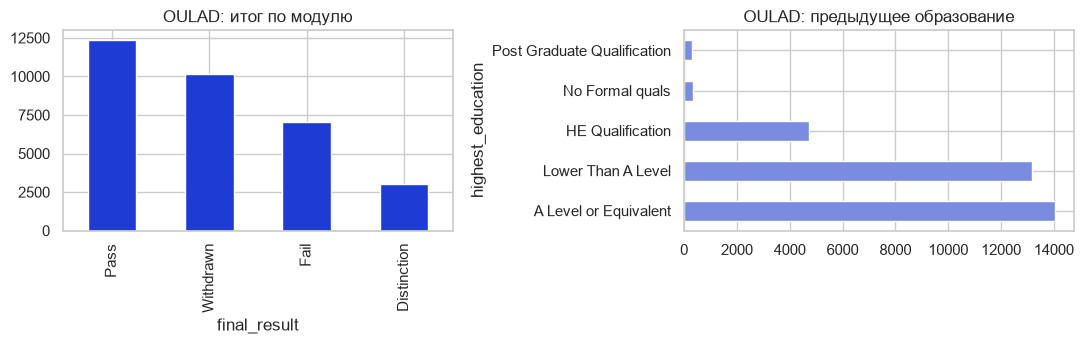

доля Withdrawn + Fail: 52.8%


In [8]:
oulad = pd.read_sql('SELECT * FROM cleaned.oulad_student_info', eng)
print('студенто-модулей:', len(oulad), 'уникальных студентов:', oulad['id_student'].nunique())
print('пропусков imd_band:', oulad['imd_band'].isna().sum(), f"({oulad['imd_band'].isna().mean():.1%})")

fig, axes = plt.subplots(1, 2, figsize=(11, 3.6))
oulad['final_result'].value_counts().plot.bar(ax=axes[0], color='#1E3CD4')
axes[0].set_title('OULAD: итог по модулю')
oulad['highest_education'].value_counts().plot.barh(ax=axes[1], color='#7A8CE0')
axes[1].set_title('OULAD: предыдущее образование')
plt.tight_layout()
plt.show()
print('доля Withdrawn + Fail:', f"{oulad['final_result'].isin(['Withdrawn', 'Fail']).mean():.1%}")

## 3. Синтетический контингент: структура и баланс

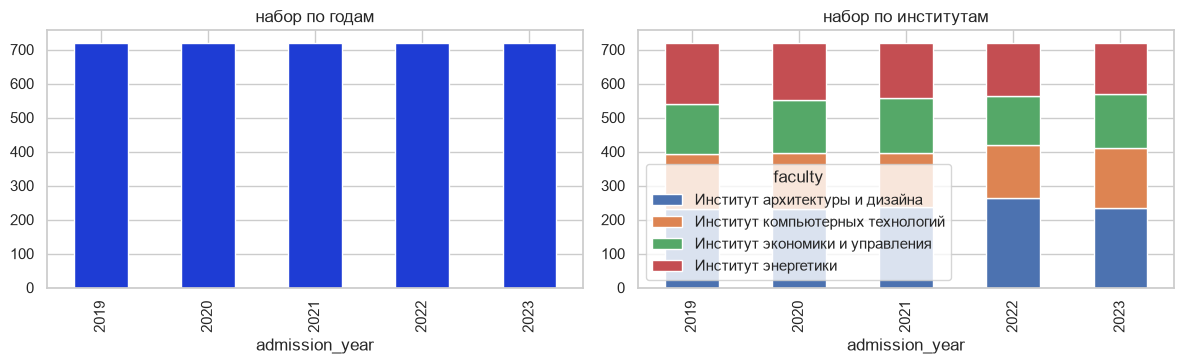

In [9]:
students = pd.read_sql('SELECT * FROM cleaned.vs_students', eng)
programs = pd.read_sql('SELECT * FROM cleaned.vs_programs', eng)
movements = pd.read_sql('SELECT * FROM cleaned.vs_movements', eng)
grades = pd.read_sql('SELECT * FROM cleaned.vs_grades', eng)
debts = pd.read_sql('SELECT * FROM cleaned.vs_debts', eng)

merged = students.merge(programs[['program_id', 'faculty']], on='program_id')
fig, axes = plt.subplots(1, 2, figsize=(12, 3.8))
merged.groupby('admission_year')['student_id'].count().plot.bar(ax=axes[0], color='#1E3CD4')
axes[0].set_title('набор по годам')
merged.groupby(['admission_year', 'faculty'])['student_id'].count().unstack().plot.bar(stacked=True, ax=axes[1])
axes[1].set_title('набор по институтам')
plt.tight_layout()
plt.show()

целевых отчислений: 837 (23.2%)
reason
академическая задолженность                     704
по собственному желанию                         301
неисполнение обязанностей по оплате обучения    133
перевод в другой вуз                             63


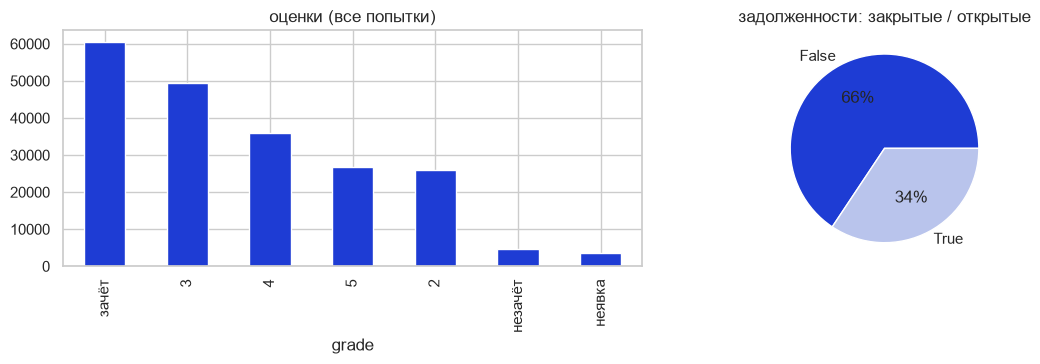

оценок: 207031 задолженностей: 5569


In [10]:
drops = movements[movements['order_type'] == 'отчисление']
positive = drops[drops['reason'].isin(['академическая задолженность', 'неисполнение обязанностей по оплате обучения'])]
print('целевых отчислений:', len(positive), f'({len(positive) / len(students):.1%})')
print(drops['reason'].value_counts().to_string())

fig, axes = plt.subplots(1, 2, figsize=(12, 3.8))
grades['grade'].value_counts().plot.bar(ax=axes[0], color='#1E3CD4')
axes[0].set_title('оценки (все попытки)')
debts['is_closed'].value_counts().plot.pie(autopct='%1.0f%%', ax=axes[1], colors=['#1E3CD4', '#B9C4EC'])
axes[1].set_title('задолженности: закрытые / открытые')
plt.tight_layout()
plt.show()
print('оценок:', len(grades), 'задолженностей:', len(debts))

## 4. Выводы EDA и решения по очистке

Найденные проблемы в данных:

1. UCI: все колонки текстовые (файл загружен как есть), в заголовках BOM
   и табуляция, опечатка Nacionality.
2. OULAD: пропуски обозначены двумя разными маркерами: '?' (оценки, вес,
   недели доступа) и пустая строка (imd_band, даты регистрации); всего
   11 + 5243 + 45 + 22521 + 173 пропущенных значений в числовых полях.
3. Синтетика: типы заданы при генерации, дополнительно нужна единая
   числовая шкала оценок (зачёт и числовые виды контроля в одном признаке).

Решения очистки (реализованы в sql/layers.sql, исполнитель src/data/clean.py):

1. Пропуски: пустая строка и '?' приводятся к NULL.
2. Коды категорий и идентификаторы приведены к целым типам, опечатка
   исправлена в cleaned (nationality).
3. Единая шкала оценок синтетики: экзамен, зачёт с оценкой и курсовой
   проект дают 2..5, зачёт эквивалентен 4, незачёт эквивалентен 2, неявка
   даёт NULL (попытка не состоялась).
4. Производные флаги: is_pass (попытка сдана), is_closed и days_open
   (задолженность), is_paid (платёж).
5. Целевая UCI: target_dropout = 1 для Dropout, иначе 0.

Балансы целевых переменных: UCI 32.1% Dropout; OULAD 52.8% Withdrawn + Fail
(учёт на уровне студент и модуль); синтетика 23.2% целевых отчислений.

In [11]:
from src.data.clean import main as run_clean

# Чтения выше шли через пул SQLAlchemy-движка. Сбрасываем пул, чтобы ни одна
# простаивающая транзакция не блокировала TRUNCATE в очистке.
eng.dispose()
run_clean()

cleaned.oulad_assessments: 206
cleaned.oulad_courses: 22
cleaned.oulad_student_assessment: 173912
cleaned.oulad_student_info: 32593
cleaned.oulad_student_registration: 32593
cleaned.oulad_student_vle: 10655280
cleaned.oulad_vle: 6364
cleaned.uci_dropout: 4424
cleaned.vs_admission: 3600
cleaned.vs_debts: 5569
cleaned.vs_disciplines: 549
cleaned.vs_finance: 13795
cleaned.vs_grades: 207031
cleaned.vs_load: 74
cleaned.vs_movements: 5156
cleaned.vs_programs: 9
cleaned.vs_students: 3600


Слой cleaned готов. Следующий шаг: слой features с признаками
«студент, семестр» и срезом на дату наблюдения (docs/experiment_plan.md,
раздел 1), затем базовая модель в notebooks/02_baseline_model.ipynb.